# 4

## (a)

In [ ]:
from itertools import combinations
from math import comb

import numpy as np
import matplotlib.pyplot as plt

from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

p = 64
k_values = [1, 2, 3, 4]
n_values = np.array([20, 40, 80, 160, 320, 640])
T = 10
rho = 0.5

designs = ["Gaussian", "Laplace", "AR(1)", "Equicorrelated", "Heavy-tailed"]

supports = {}

for k in k_values:
    count = comb(p, k)
    indices = np.fromiter(
        (j for support in combinations(range(p), k) for j in support),
        dtype=np.uint8,
        count=count * k
    )
    supports[k] = indices.reshape(count, k)
    print(f"k={k}: {count:,} supports")

k=1: 64 supports
k=2: 2,016 supports
k=3: 41,664 supports
k=4: 635,376 supports


In [3]:
def generate_design(design, n, p, rng, rho=0.5):
    if design == "Gaussian":
        return rng.standard_normal((n, p))
    elif design == "Laplace":
        return rng.laplace(
            loc=0.0,
            scale=1 / np.sqrt(2),
            size=(n, p)
        )
    elif design == "AR(1)":
        z = rng.standard_normal((n, p))
        X = np.empty((n, p))

        X[:, 0] = z[:, 0]

        for j in range(1, p):
            X[:, j] = (
                rho * X[:, j - 1]
                + np.sqrt(1 - rho**2) * z[:, j]
            )

        return X
    elif design == "Equicorrelated":
        z = rng.standard_normal((n, p))
        g = rng.standard_normal((n, 1))

        return (
            np.sqrt(1 - rho) * z
            + np.sqrt(rho) * g
        )
    elif design == "Heavy-tailed":
        return rng.standard_t(
            df=2.2, size=(n, p)
        ) / np.sqrt(11)

def compute_all_delta(X, supports, batch_size=20000):
    n, p = X.shape
    G = (X.T @ X) / n

    deltas = np.empty(4, dtype=float)

    deltas[0] = np.max(np.abs(np.diag(G) - 1))

    pairs = supports[2]
    a = G[pairs[:, 0], pairs[:, 0]]
    b = G[pairs[:, 1], pairs[:, 1]]
    c = G[pairs[:, 0], pairs[:, 1]]

    center = (a + b) / 2
    radius = np.sqrt(((a - b) / 2)**2 + c**2)

    deltas[1] = np.max(np.abs(center - 1) + radius)

    for k in [3, 4]:
        indices = supports[k]
        maximum = 0.0

        for start in range(0, len(indices), batch_size):
            batch = indices[start:start + batch_size]

            gram_blocks = G[
                batch[:, :, None],
                batch[:, None, :]
            ]

            eigenvalues = np.linalg.eigvalsh(gram_blocks)

            deviations = np.maximum(
                np.abs(eigenvalues[:, 0] - 1),
                np.abs(eigenvalues[:, -1] - 1)
            )

            maximum = max(maximum, float(deviations.max()))

        deltas[k - 1] = maximum

    return deltas

def run_trial(design_idx, n_idx, trial_idx, seed):
    design = designs[design_idx]
    n = int(n_values[n_idx])
    rng = np.random.default_rng(seed)

    with threadpool_limits(limits=1):
        X = generate_design(design, n, p, rng, rho)
        delta_values = compute_all_delta(
            X, supports, 20000
        )

    return design_idx, n_idx, trial_idx, delta_values

configs = [
    (d, ni, t)
    for d in range(len(designs))
    for ni in range(len(n_values))
    for t in range(T)
]

seeds = np.random.SeedSequence(0).spawn(len(configs))

trial_results = Parallel(
    n_jobs=8,
    backend="loky",
    verbose=10
)(
    delayed(run_trial)(d, ni, t, seeds[i])
    for i, (d, ni, t) in enumerate(configs)
)

delta = np.zeros(
    (len(designs), len(k_values), len(n_values), T)
)

for d, ni, t, delta_values in trial_results:
    delta[d, :, ni, t] = delta_values

means = delta.mean(axis=3)
sems = delta.std(axis=3, ddof=1) / np.sqrt(T)

np.savez(
    "results_4a.npz",
    delta=delta,
    means=means,
    sems=sems,
    n_values=n_values,
    k_values=k_values,
    designs=np.array(designs),
    T=T
)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    1.2s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    1.9s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    2.0s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    3.3s
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    4.0s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:    4.7s
[Parallel(n_jobs=8)]: Done  56 tasks      | elapsed:    5.6s
[Parallel(n_jobs=8)]: Done  69 tasks      | elapsed:    6.9s
[Parallel(n_jobs=8)]: Done  82 tasks      | elapsed:    8.3s
[Parallel(n_jobs=8)]: Done  97 tasks      | elapsed:    9.8s
[Parallel(n_jobs=8)]: Done 112 tasks      | elapsed:   10.8s
[Parallel(n_jobs=8)]: Done 129 tasks      | elapsed:   12.8s
[Parallel(n_jobs=8)]: Done 146 tasks      | elapsed:   14.3s
[Parallel(n_jobs=8)]: Done 165 tasks      | elapsed:   15.8s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:   17.3s
[Parallel(

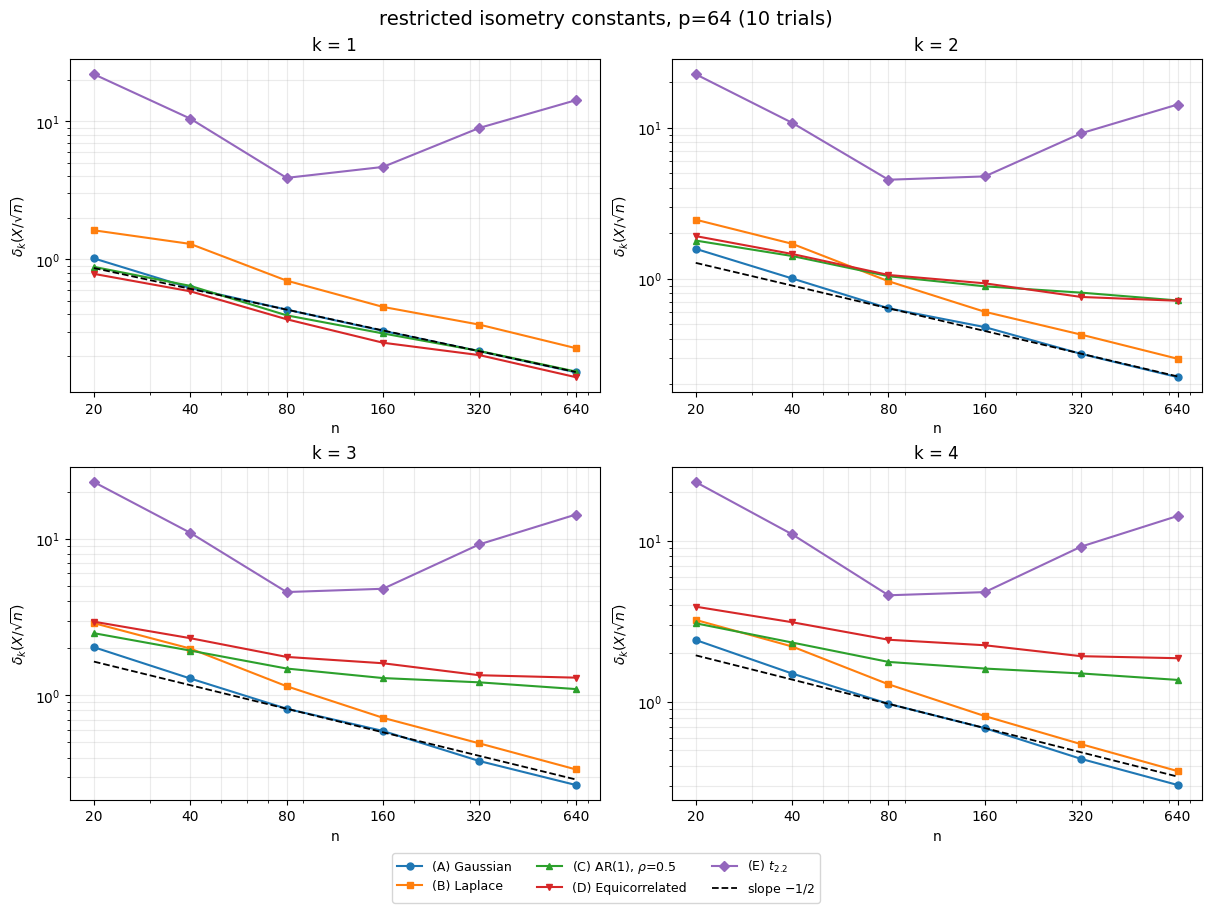

In [10]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    layout="constrained"
)

markers = ["o", "s", "^", "v", "D"]

design_labels = ["(A) Gaussian", "(B) Laplace", r"(C) AR(1), $\rho$=0.5", "(D) Equicorrelated", r"(E) $t_{2.2}$"]

for ki, k in enumerate(k_values):
    ax = axes.flat[ki]

    for d, design_label in enumerate(design_labels):
        ax.plot(
            n_values,
            means[d, ki, :],
            marker=markers[d],
            linewidth=1.5,
            markersize=5,
            label=design_label
        )

    reference = means[0, ki, 2] * (n_values / 80)**(-0.5)

    ax.plot(
        n_values,
        reference,
        "k--",
        linewidth=1.3,
        label=r"slope $-1/2$"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_title(f"k = {k}")
    ax.set_xlabel("n")
    ax.set_ylabel(r"$\delta_k(X/\sqrt{n})$")

    ax.set_xticks(n_values)
    ax.set_xticklabels(n_values)

    ax.grid(True, which="both", alpha=0.25)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="outside lower center",
    ncol=3,
    fontsize=9
)

fig.suptitle(
    f"restricted isometry constants, p={p} ({T} trials)",
    fontsize=14
)

plt.show()

In [11]:
means[3, :, -1]

array([0.14057132, 0.7134392 , 1.29582759, 1.86817295])

i. $\delta_k$ decays like $n^{-1/2}$ for designs (A) and (B). Despite being
not sub-Gaussian, design (B) is consistent with its finite moments and exponetial
tails. The entries of the sample Gram matrix still concentrate at approximately
$n^{-1/2}$ rate for fixed $p$ and $k$.  
ii. For both (C) and (D), the rows have covariance matrix $\Sigma$. By the law
of large numbers, $\frac{1}{n}X^\top X\xrightarrow\Sigma$. Therefore, for fixed
$p$ and $k$, $\lim_{n\to\infty}\delta_k=\max_{|T|=k}\|\Sigma_{TT}-I_k\|_{\mathrm{op}}$.
For design (C), $\Sigma_{ij} = \rho^{|i - j|}$, $\rho = 0.5$. Since the off diagonal
correlations do not vanish, $\delta_k$ approaches a positive limit for $k \geq 2$,
which we see in the simulations as the curve begins to flatten for larger $k$ and 
$n$. For design (D), $\Sigma = (1 - \rho)I_p + \rho\mathbf1\mathbf1^\top$. For a support
$T$ with $|T| = k$, we have $\Sigma_{TT} - I_k = \rho(\mathbf1_k\mathbf1_k^\top - I_k)$,
and thus the eigenvalues are $\rho(k - 1), -\rho, \cdots, -\rho$. Then, the limiting
restricted isometry constant is $\lim_{n\to\infty}\delta_k = \begin{cases}
0, & k=1 \\
\rho(k-1), & k\geq2
\end{cases}$ For $\rho = 0.5$, the theoretical limit of $k = 1,2,3,4$ is respectively
$0, 0.5, 1, 1.5$, which the simulated values approach but remain slightly above them
at $n = 640$. Then, a correlated design can satisfy $k$-RIP with a small constant
if its population covariance is sufficiently close to the identity on every $k$-sparse
support. However, increasing $n$ cannot eliminate the underlying correlations. For
design (D), $\rho(k - 1)$ sets the limiting RIP constant, so strong correlations
prevent a small RIP constant as $n \to \infty$.  
iii. Design (E) is significantly different from the rest of the designs. Its
restricted isometry constant does not consistently decrease as $n$ grows. For $k = 1$,
the column norms ($\delta_1 =\max_j\left|\frac1n\sum_{i=1}^nX_{ij}^2-1\right|$) 
are highly unstable because the fourth moment $E[X_{ij}^4] = \infty$, therefore
$X_{ij}^2$ has infinite variance leading to large fluctuations which we see in the
graphs, especially for larger $n$. The RIP proof from Lecture 9 assumes a sub-Gaussian
condition, which requires $(x_i^\top u)^2 - 1$ to be sub-exponential so that 
Bernstein's inequality provides exponential concentration. However, the Student's 
$t_{2.2}$ design does not satisfy this requirement.

## (b)

In [ ]:
from sklearn.linear_model import Lasso

P = 512
K = 10
N_VALUES = np.array([200, 400, 800, 1600, 3200])
DESIGNS = ["(A) Gaussian", r"(D) equicorrelated $\rho$=0.5", r"(E) $t_{2.2}$",
           "(F) duplicated column", "(G) factor model, r=5"]
TRIALS = 20
SEED = 0
RHO = 0.5
FACTOR_RANK = 5

def generate_data(design_index, n, rng):
    beta = np.zeros(P)
    if design_index == 3:
        available = np.arange(2, P)
        support = np.r_[1, rng.choice(available, size=K - 1, replace=False)]
    else:
        support = rng.choice(P, size=K, replace=False)
    beta[support] = rng.choice(np.array([-1.0, 1.0]), size=K)

    # A, F
    if design_index == 0 or design_index == 3:
        X = rng.standard_normal((n, P))
        if design_index == 3:
            X[:, 0] = X[:, 1]
    # D
    elif design_index == 1:
        z = rng.standard_normal((n, P))
        g = rng.standard_normal((n, 1))
        X = np.sqrt(1 - RHO) * z + np.sqrt(RHO) * g
    # E
    elif design_index == 2:
        X = rng.standard_t(df=2.2, size=(n, P)) / np.sqrt(11)
    # G
    else:
        V = rng.standard_normal((P, FACTOR_RANK))
        V = V / np.linalg.norm(V, axis=1, keepdims=True)
        latent = rng.standard_normal((n, FACTOR_RANK))
        X = latent @ V.T

    eps = rng.standard_normal(n)
    y = X @ beta + eps
    return X, beta, eps, y

def run_trial(design_index, n_index, trial_index, seed):
    n = int(N_VALUES[n_index])
    rng = np.random.default_rng(seed)
    X, beta, eps, y = generate_data(design_index, n, rng)
    lambda0 = np.sqrt(2 * np.log(P) / n)
    lam = 0.5 * lambda0

    with threadpool_limits(limits=1):
        solver = Lasso(alpha=lam, fit_intercept=False,
                       max_iter=50000, tol=1e-8, selection="cyclic")
        solver.fit(X, y)
    delta = solver.coef_ - beta
    estimation = float(delta @ delta)
    residual = X @ delta
    prediction = float((residual @ residual) / n)
    noise_ratio = float(np.max(np.abs(X.T @ eps / n)) / lambda0)
    if design_index == 3:
        beta_hat_1 = float(solver.coef_[0])
        beta_hat_2 = float(solver.coef_[1])
    else:
        beta_hat_1 = np.nan
        beta_hat_2 = np.nan
    return (design_index, n_index, trial_index, estimation, prediction,
            noise_ratio, beta_hat_1, beta_hat_2, bool(solver.n_iter_ >= solver.max_iter))

configs = [(d, ni, t) for d in range(len(DESIGNS))
            for ni in range(len(N_VALUES)) for t in range(TRIALS)]
seeds = np.random.SeedSequence(0).spawn(len(configs))
result_rows = Parallel(n_jobs=8, backend="loky", verbose=10)(
    delayed(run_trial)(d, ni, t, seeds[index])
    for index, (d, ni, t) in enumerate(configs)
)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    2.5s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    2.5s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Batch computation too fast (0.19974150234096363s.) Setting batch_size=2.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Batch computation too fast (0.06576704978942871s.) Setting batch_size=4.
[Parallel(n_jobs=8)]: Done  64 tasks      | elapsed:    2.7s
[Parallel(n_jobs=8)]: Done 100 tasks      | elapsed:    3.0s
[Parallel(n_jobs=8)]: Done 152 tasks      | elapsed:    3.3s
[Parallel(n_jobs=8)]: Done 212 tasks      | elapsed:    4.5s
[Parallel(n_jobs=8)]: Done 272 tasks      | elapsed:    5.7s
[Parallel(n_jobs=8)]: Done 340 tasks      | elapsed:    6.2s
[Pa

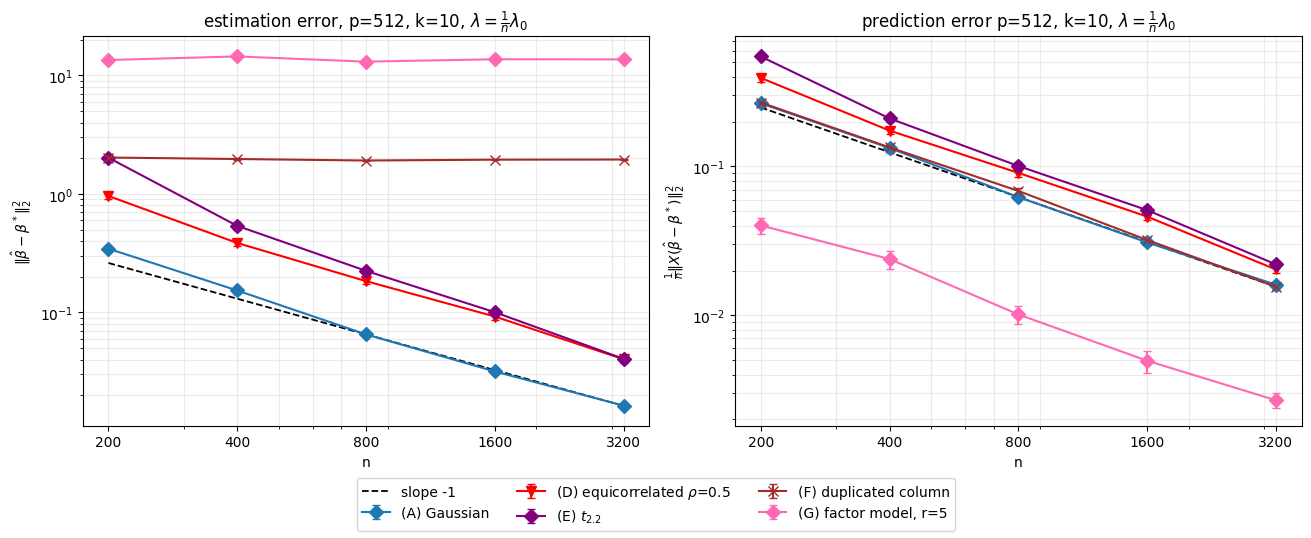


Noise ratio E[||X.T eps/n||_inf] / lambda0
n       Gaussian mean  Gaussian SEM  t(2.2) mean  t(2.2) SEM
200            0.9263        0.0178        2.4265        0.3740
400            0.9335        0.0219        2.2622        0.4071
800            0.9110        0.0319        2.5482        0.4971
1600           0.8937        0.0240        1.9249        0.3607
3200           0.9554        0.0235        1.5739        0.1641

Duplicated-column solver behavior (F):
n=200: average beta_hat[0]=-0.11785, beta_hat[1]=0.00000, fraction |beta_hat[0]|>1e-6=1.00
n=400: average beta_hat[0]=0.38528, beta_hat[1]=0.00000, fraction |beta_hat[0]|>1e-6=1.00
n=800: average beta_hat[0]=0.09976, beta_hat[1]=-0.00000, fraction |beta_hat[0]|>1e-6=1.00
n=1600: average beta_hat[0]=-0.18843, beta_hat[1]=-0.00000, fraction |beta_hat[0]|>1e-6=1.00
n=3200: average beta_hat[0]=0.19527, beta_hat[1]=0.00000, fraction |beta_hat[0]|>1e-6=1.00


In [28]:
est = np.empty((len(DESIGNS), len(N_VALUES), TRIALS))
pred = np.empty_like(est)
noise = np.empty_like(est)
duplicates = np.full((len(N_VALUES), TRIALS, 2), np.nan)
n_nonconverged = 0
for d, ni, t, a, b, c, b1, b2, warn in result_rows:
    est[d, ni, t] = a
    pred[d, ni, t] = b
    noise[d, ni, t] = c
    if d == 3:
        duplicates[ni, t] = [b1, b2]
    n_nonconverged += int(warn)

def summarize(data):
    return data.mean(axis=2), data.std(axis=2, ddof=1) / np.sqrt(TRIALS)

est_mean, est_sem = summarize(est)
pred_mean, pred_sem = summarize(pred)
noise_mean, noise_sem = summarize(noise)
np.savez("results_4b.npz", est=est, pred=pred, noise=noise,
            duplicates=duplicates, est_mean=est_mean, est_sem=est_sem,
            pred_mean=pred_mean, pred_sem=pred_sem,
            noise_mean=noise_mean, noise_sem=noise_sem, n_values=N_VALUES,
            designs=np.array(DESIGNS), trials=TRIALS, seed=0)

styles = [
    {"color": "tab:blue",    "marker": "D"},
    {"color": "red",     "marker": "v"},
    {"color": "purple",  "marker": "D"},
    {"color": "brown",   "marker": "x"},
    {"color": "hotpink", "marker": "D"}
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), layout="constrained")
for ax, mean, sem, title, ylabel in (
    (axes[0], est_mean, est_sem, r"estimation error, p=512, k=10, $\lambda = \frac{1}{n}\lambda_0$", r"$\|\hat\beta-\beta^*\|_2^2$"),
    (axes[1], pred_mean, pred_sem, r"prediction error p=512, k=10, $\lambda = \frac{1}{n}\lambda_0$", r"$\frac{1}{n}\|X(\hat\beta-\beta^*)\|_2^2$")
):
    for d, name in enumerate(DESIGNS):
        style = styles[d]

        ax.errorbar(
            N_VALUES,
            mean[d],
            yerr=sem[d],
            fmt="-",
            color=style["color"],
            marker=style["marker"],
            markersize=7,
            capsize=3,
            linewidth=1.5,
            label=name
        )
    anchor = mean[0, 2]
    ref = anchor * (N_VALUES / N_VALUES[2]) ** (-1)
    ax.plot(N_VALUES, ref, "k--", linewidth=1.3, label="slope -1")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(N_VALUES)
    ax.set_xticklabels([str(x) for x in N_VALUES])
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel(ylabel)
    ax.grid(which="both", alpha=0.25)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
plt.show()

print("\nNoise ratio E[||X.T eps/n||_inf] / lambda0")
print("n       Gaussian mean  Gaussian SEM  t(2.2) mean  t(2.2) SEM")
for ni, n in enumerate(N_VALUES):
    print(f"{n:<7d} {noise_mean[0,ni]:13.4f} {noise_sem[0,ni]:13.4f} "
            f"{noise_mean[2,ni]:13.4f} {noise_sem[2,ni]:13.4f}")

print("\nDuplicated-column solver behavior (F):")
for ni, n in enumerate(N_VALUES):
    print(f"n={n}: average beta_hat[0]={duplicates[ni,:,0].mean():.5f}, "
            f"beta_hat[1]={duplicates[ni,:,1].mean():.5f}, "
            f"fraction |beta_hat[0]|>1e-6={np.mean(np.abs(duplicates[ni,:,0])>1e-6):.2f}")

i. From part (a), design (D) does not satisfy $k$-RIP with a small constant when $k$
is large, since its population covariance is $\Sigma = (1 - \rho)I_p + \rho\mathbf{1}\mathbf{1}^\top$.
However, LASSO only requires the RE condition, which is weaker than RIP. So, for 
any $u \in \mathbb{R}^p$, $u^\top \Sigma u = (1 - \rho)\|u\|_2^2 + \rho(\mathbf{1}^\top u)^2 \geq (1 - \rho)\|u\|_2^2$, since $\rho(\mathbf{1}\top u)^2 \geq 0$. Thus, $u^\top \Sigma u \geq \lambda_\text{min}(\Sigma)\|u\|_2^2$.
The eigenvalues of $\Sigma$ are $1 - \rho$ (multiplicity $p - 1$), and $1 + (p - 1)\rho$ (multiplicity 1).
Therefore, for any $\rho = 0.5$, $\lambda_\text{min}(\Sigma) = 1 - \rho = 0.5$,
and $u^\top \Sigma u \geq 0.5\|u\|_2^2$. This establishes the RE condition with
$\kappa = 0.5$, even for all vectors $u$. According to the LASSO bound, $\|\hat{\beta} - \beta^*\|_2 \leq \frac{3\lambda\sqrt{k}}{\kappa}$. Since $\lambda^2\asymp\log(p)/n$, the squared estimation
error is expected to decrease at approximately fast rate $1/n$ when the sample RE
condition is sufficiently controlled. The LASSO analysis then uses the lower side
of the restricted isometric inequality $\frac{1}{n}\|Xu\|_2^2 \geq \kappa\|u\|_2^2$,
allowing a correlated design to violate small constant RIP and still permit accurate
LASSO estimation.  

ii. Design (E) generally has larger estimation errors than design (A), but both
estimation and prediction errors decrease as the sample size increases. However, (E) has less stable recovery due to its larger observations. We can see that the
Gaussian noise levels remain around 0.9, while the heavy tailed ratios are consistently
larger, ranging from 1.5 to 2.5, almost a 2x increase. Since $\lambda = \frac{1}{2}\lambda_0$,
the noise condition requires $\|\frac{1}{n}X^\top\epsilon\|_\infty \leq \frac{\lambda_0}{4}$.
The reported noise ratios are much greater than 0.25, thus chosen regularization
levels do not reliably enforce (N). Heavy tails also affect the design condition,
since extreme observations make the sample Gram matrix less stable, which we can
see with the irregular restriced isometry constants. Thus, from the reported table
and panels, we can see t hat heavy tails affects both conditions.  

iii. In (F), since column 1 is a duplicate of column 2, $X_1 = X_2$, and the true
support $S$ will always contain coordinate 2 but never coordinate 1. Consider
the nonzero vector $\Delta = e_1 - e_2$. Because the columns are identical, $X\Delta = X_1 - X_2 = 0$.
Also, $\|\Delta_{S^c}\|_1 = 1$ and $\|\Delta_S\|_1 = 1$. Therefore, $\Delta$ satisfies
the cone condition, but $\frac{1}{n}\|X\Delta\|_2^2 = 0$ and $\|\Delta\|_2^2 = 2$,
thus the restricted eigenvalue identity $\frac{1}{n}\|X\Delta\|_2^2 \geq \kappa\|\Delta\|_2^2$
can't hold for any $\kappa > 0$. Therefore, the RE condition fails for design (F).
For design (G), the factor model is $X = GV^\top$. Since both matrices have 5 columns
and are full column rank almost surely, the rank of X is 5. The true support has 
size $|S| = 10$, therefore $rank(X_s)\leq5\leq10$. Thus, the 10 columns of $X_S$
are linearly dependent, meaning there exists a nonzero vector $\Delta$ supported
on $S$ such that $X\Delta = 0$. Since $\Delta$ is supported entirely on $S$, 
$\|\Delta_{S^c}\|_1 = 0 \leq 3 \|\Delta_S\|_1$, but again, $\frac{1}{n}\|X\Delta\|_2^2 = 0 < \kappa\|\Delta\|_2^2$,
for every $\kappa > 0$, and hence, the RE condition also fails for design (G). Because
both designs have nonzero vectors in the null space of $X$, different coefficient
vectors can produce the same response. Therefore, the true coefficient vector is 
not uniquely identifiable, even as $n\to\infty$. Consequently, the squared estimation
error doesn't need to converge to 0, but the prediction error can approach 0 because
the estimator can accurately recover $X\beta^*$ without recovering the exact
coefficients. We can see this in the simulation, as designs (F) and (G) exhibit
decrease prediction errors but persistent estimation errors. For design (F), I
used `sklearn.linear_model.Lasso` with cyclic coordinate descent (`selection='cyclic'`).
Across all 100 trials, the solver assigned the nonzero duplicated-column coefficient 
to coordinate 1, while coordinate 2 remained approximately zero. Since $X_1 = X_2$,
$X_1\hat\beta_1+X_2\hat\beta_2=X_2(\hat\beta_1+\hat\beta_2)$. Therefore, the fitted
response only depends on the sum of the two coefficients. When this sum is nonzero, 
multiple allocations with the same sign and total magnitude produce the same fitted 
response and $\ell_1$ penalty, so the LASSO minimizer is not unique. The cyclic 
coordinate-descent solver updates coordinate 1 first, allowing it to absorb the 
shared coefficient while coordinate 2 remains zero. The reported average of $\hat\beta_1$ 
changes sign because the true coefficient is randomly $\pm1$ across trials. Thus, 
the solver can produce accurate predictions while assigning the coefficient to 
the wrong variable.

## (c)

In [30]:
P, K, N = 512, 10, 800
RHOS = np.array([0, 0.5, 0.8, 0.9, 0.95, 0.98, 0.99])
TRIALS = 20
SEED = 0

LAMBDA0 = np.sqrt(2 * np.log(P) / N)
LAM = 0.5 * LAMBDA0

def run_trial(rho_index, trial_index, seed):
    rho = float(RHOS[rho_index])
    rng = np.random.default_rng(seed)

    # True k-sparse coefficient vector
    beta = np.zeros(P)
    support = rng.choice(P, size=K, replace=False)
    beta[support] = rng.choice([-1.0, 1.0], size=K)

    # Equicorrelated Gaussian design
    z = rng.standard_normal((N, P))
    common = rng.standard_normal((N, 1))
    X = np.sqrt(1 - rho) * z + np.sqrt(rho) * common

    # Response
    eps = rng.standard_normal(N)
    y = X @ beta + eps

    # LASSO fit
    with threadpool_limits(limits=1):
        solver = Lasso(
            alpha=LAM,
            fit_intercept=False,
            max_iter=50000,
            tol=1e-8,
            selection="cyclic"
        )
        solver.fit(X, y)

    delta = solver.coef_ - beta

    estimation = float(delta @ delta)
    Xdelta = X @ delta
    prediction = float(Xdelta @ Xdelta / N)

    noise_ratio = float(
        np.max(np.abs(X.T @ eps / N)) / LAMBDA0
    )

    nonconverged = solver.n_iter_ >= solver.max_iter

    return (
        rho_index,
        trial_index,
        estimation,
        prediction,
        noise_ratio,
        nonconverged
    )

configs = [
    (i, t)
    for i in range(len(RHOS))
    for t in range(TRIALS)
]

seeds = np.random.SeedSequence(0).spawn(
    len(configs)
)

results = Parallel(
    n_jobs=8,
    backend="loky",
    verbose=5
)(
    delayed(run_trial)(i, t, seeds[index])
    for index, (i, t) in enumerate(configs)
)

estimation = np.empty((len(RHOS), TRIALS))
prediction = np.empty_like(estimation)
noise_ratio = np.empty_like(estimation)

nonconverged = 0

for i, t, e, q, r, warning in results:
    estimation[i, t] = e
    prediction[i, t] = q
    noise_ratio[i, t] = r
    nonconverged += int(warning)

mean_est = estimation.mean(axis=1)
mean_pred = prediction.mean(axis=1)

sem_est = (
    estimation.std(axis=1, ddof=1) / np.sqrt(TRIALS)
)
sem_pred = (
    prediction.std(axis=1, ddof=1) / np.sqrt(TRIALS)
)

fast = 9 * K * LAM**2 / (1 - RHOS)
slow = 3 * LAM * K

np.savez(
    "results_4c.npz",
    rhos=RHOS,
    estimation=estimation,
    prediction=prediction,
    noise_ratio=noise_ratio,
    mean_est=mean_est,
    mean_pred=mean_pred,
    sem_est=sem_est,
    sem_pred=sem_pred,
    bound_fast=fast,
    bound_slow=slow,
    seed=SEED,
    trials=TRIALS
)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    2.7s
[Parallel(n_jobs=8)]: Done  64 tasks      | elapsed:    3.5s
[Parallel(n_jobs=8)]: Done 125 out of 140 | elapsed:   10.1s remaining:    1.1s
[Parallel(n_jobs=8)]: Done 140 out of 140 | elapsed:   15.5s finished


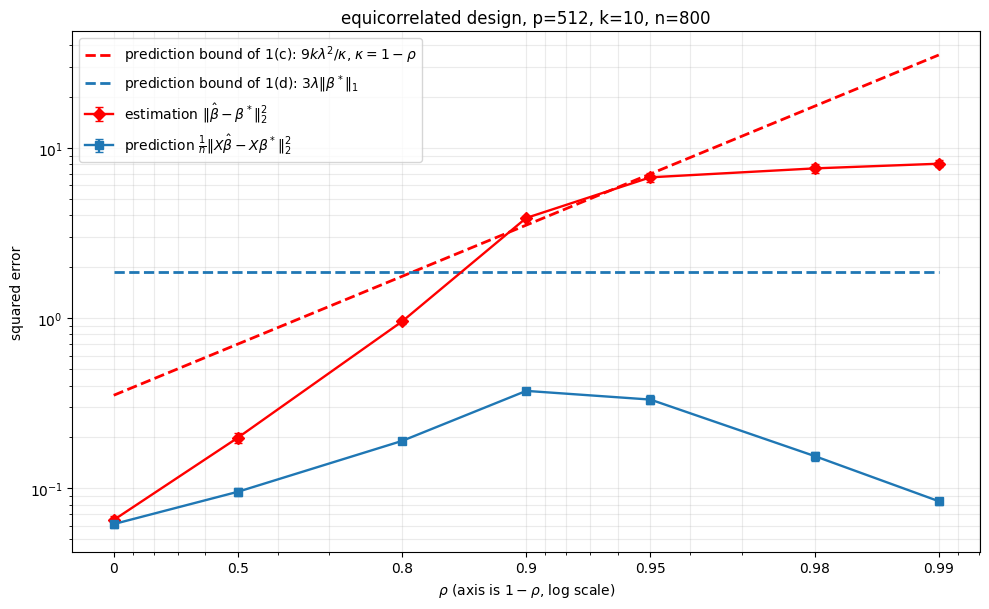

rho    est mean   est SEM  pred mean  pred SEM  fast bound  slow bound
0.00     0.0649    0.0039     0.0614    0.0032      0.3509      1.8732
0.50     0.1977    0.0138     0.0951    0.0056      0.7018      1.8732
0.80     0.9523    0.0304     0.1892    0.0055      1.7545      1.8732
0.90     3.8665    0.1191     0.3724    0.0082      3.5091      1.8732
0.95     6.7022    0.3943     0.3310    0.0200      7.0181      1.8732
0.98     7.5633    0.4128     0.1542    0.0095     17.5453      1.8732
0.99     8.0551    0.3727     0.0837    0.0037     35.0906      1.8732


In [37]:
fig, ax = plt.subplots(figsize=(10, 6.2))

x = 1 - RHOS

ax.errorbar(
    x, mean_est,
    yerr=sem_est,
    fmt="D-",
    color="red",
    capsize=3,
    linewidth=1.7,
    markersize=6,
    label=r"estimation $\|\hat{\beta} - \beta^*\|_2^2$"
)

ax.errorbar(
    x, mean_pred,
    yerr=sem_pred,
    fmt="s-",
    color="tab:blue",
    capsize=3,
    linewidth=1.7,
    markersize=6,
    label=r"prediction $\frac{1}{n}\|X\hat{\beta} - X\beta^*\|_2^2$"
)

ax.plot(
    x, fast,
    "--",
    color="red",
    linewidth=2,
    label=r"prediction bound of 1(c): $9k\lambda^2/\kappa$, $\kappa = 1 - \rho$"
)

ax.plot(
    x, np.full_like(x, slow),
    "--",
    color="tab:blue",
    linewidth=2,
    label=r"prediction bound of 1(d): $3\lambda\|\beta^*\|_1$"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xticks(x)
ax.set_xticklabels([f"{rho:g}" for rho in RHOS])

ax.invert_xaxis()

ax.set_xlabel(r"$\rho$ (axis is $1-\rho$, log scale)")
ax.set_ylabel("squared error")
ax.set_title("equicorrelated design, p=512, k=10, n=800")

ax.grid(True, which="both", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

print(
    "rho    est mean   est SEM  "
    "pred mean  pred SEM  fast bound  slow bound"
)

for i, rho in enumerate(RHOS):
    print(
        f"{rho:4.2f}  "
        f"{mean_est[i]:9.4f} {sem_est[i]:9.4f}  "
        f"{mean_pred[i]:9.4f} {sem_pred[i]:9.4f} "
        f"{fast[i]:11.4f} {slow:11.4f}"
    )

As $\rho \to 1$, the estimatino error increases, while the prediction error initially
increases then decreases. This occurs because, as $\rho \to 1$, the columns of $X$
become nearly identical. Consequently, it becomes increasingly difficult to 
distinguish individual coefficients, even though the model can still accurately 
predict the response. Therefore, high correlation substantially worsens coefficient 
estimation but doesn't necessarily worsen prediction accuracy. Both bounds are 
respected by the empirical mean prediction error at every tested $\rho$. However, 
this does not guarantee that every individual trial satisfies the bounds, since 
the theoretical guarantees require the noise condition (N), and the fast-rate 
bound additionally requires the sample restricted eigenvalue condition (RE). As
$\rho \to 1$, the fast bound diverges to $\infty$, while the slow bound remains
constant. Thus, the slow bound is more informative for $\rho$ close to 1. When
$\rho$ is close to 1, the columns of $X$ become nearly identical, making it difficult
to recover the true coefficients. Thus, the estimation error can remain large
even when the prediction error is small. Consider $\Delta = e_1 - e_2$. The squared
estimation error is $\|\Delta\|_2^2 = 2$, but the expected prediction error is
$E[\frac{1}{n}\|X\Delta\|2_2] = \Delta^\top \Sigma\Delta = 2(1 - \rho)$. As
$\rho \to 1$, the prediction error approaches zero, while the estimation error 
remains 2, which we can see in the plot at $\rho = 0.99$, the estimation error
is high at 8.0551 but the prediction error is only 0.0837. High correlation can 
prevent accurate coefficient recovery while still allowing accurate predictions.